# Exercice complet : l'électricité dans 12 quartiers

Une compagnie d'électricité (fictive) vous confie deux ans de relevés, de janvier 2024 à décembre 2025, pour 12 quartiers de Port-au-Prince, Delmas, Pétion-Ville et Cap-Haïtien. Le fichier arrive **brut**. Le directeur veut savoir :

> **La consommation suit-elle la chaleur, ou les heures de courant ?**

| Fichier | Une ligne par | Colonnes |
|---|---|---|
| `donnees/consommation_brut.csv` | quartier et mois | `mois`, `quartier`, `kwh` (consommation totale du quartier), `heures_courant` (heures de courant par jour, en moyenne) |
| `donnees/quartiers.csv` | quartier | `quartier`, `commune`, `type` (Résidentiel ou Commercial), `abonnes` |
| `donnees/meteo.csv` | commune et mois | `mois`, `commune`, `temperature_c`, `pluie_mm` |

Ce notebook suit **le même plan que celui du projet final** : diagnostic, nettoyage, jointures (qui écrivent le fichier propre), une partie par question, conclusion. Chaque étape donne le résultat **attendu** : vérifiez le vôtre avant de passer à la suite.

Deux livrables : **ce notebook**, exécuté du début à la fin (Restart, puis Run All), qui montre votre démarche, et **le tableau de bord `app.py`, en ligne**, qui montre vos résultats au directeur.

## 1. Diagnostic

Forme, types, valeurs manquantes, lignes en double, écritures différentes. On note chaque problème : on le corrigera à l'étape 2.

**1.** Lisez `consommation_brut.csv` dans `brut`. Donnez sa forme, le type de chaque colonne, le nombre de valeurs manquantes par colonne et le nombre de lignes en double.

Attendu : `(300, 4)` ; `kwh` est du texte (`str`) ; 9 manquants dans `kwh` ; 12 lignes en double.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

brut = pd.read_csv("donnees/consommation_brut.csv")
quartiers = pd.read_csv("donnees/quartiers.csv")
meteo = pd.read_csv("donnees/meteo.csv")
reference = pd.read_csv("donnees/consommation.csv")

print(brut.shape)
print(brut.dtypes)
print(brut.isna().sum())
print("Doublons :", brut.duplicated().sum())

(300, 4)
mois                  str
quartier              str
kwh                   str
heures_courant    float64
dtype: object
mois              0
quartier          0
kwh               9
heures_courant    0
dtype: int64
Doublons : 12


**2.** Combien d'écritures différentes pour la colonne `quartier` ? Il y a pourtant 12 quartiers.

Attendu : 43 écritures.

In [2]:
print(brut["quartier"].nunique())

43


**3.** Pourquoi `kwh` n'est-il pas un nombre ? Affichez les valeurs que `pd.to_numeric(..., errors="coerce")` ne sait pas convertir (sans compter les vrais manquants).

Attendu : des valeurs comme « 184410 kWh » ou « 251 900 ».

In [3]:
converti = pd.to_numeric(brut["kwh"], errors="coerce")
invalides = brut.loc[converti.isna() & brut["kwh"].notna(), "kwh"]
print(invalides.head(10).tolist())

['184410 kWh', '206280 kWh', '215140 kWh', '251 900', '274520 kWh', '301740 kWh', '233010 kWh', '155930 kWh', '212510 kWh', '424110 kWh']


## 2. Nettoyage

Une copie `propre`, puis une cellule par problème du diagnostic, en comptant à chaque fois.

**Contrôle :** à la fin, `propre.shape` vaut `(279, 4)` et `propre` est identique au fichier de référence.

**4.** Dans une copie `propre`, convertissez `kwh` en nombre : retirez « kWh » et les espaces, puis `pd.to_numeric`. Combien reste-t-il de manquants ?

Attendu : 9 manquants, les vrais.

In [4]:
propre = brut.copy()
propre["kwh"] = propre["kwh"].str.replace(r"(?i)kwh|\s", "", regex=True)
propre["kwh"] = pd.to_numeric(propre["kwh"])
print(propre["kwh"].isna().sum())

9


**5.** Harmonisez les noms de quartiers. Attention : `.str.title()` transforme « Bas-Peu-de-Chose » en « Bas-Peu-De-Chose ». Utilisez plutôt les noms officiels de `quartiers.csv`, avec un dictionnaire qui part des noms en minuscules.

Attendu : 12 quartiers, aucun nom perdu par `map`.

In [5]:
officiels = {nom.lower(): nom for nom in quartiers["quartier"]}
cle = propre["quartier"].str.lower().str.split().str.join(" ")
propre["quartier"] = cle.map(officiels)
print(propre["quartier"].nunique(), propre["quartier"].isna().sum())

12 0


**6.** Supprimez les doublons, puis les lignes sans `kwh` (avec `subset`). Combien de lignes reste-t-il ?

Attendu : `(279, 4)`.

In [6]:
propre = propre.drop_duplicates()
propre = propre.dropna(subset=["kwh"])
print(propre.shape)

(279, 4)


**7.** Quatre relevés ont été saisis 10 fois trop grands. Trouvez-les avec la règle « plus de 3 fois la médiane de son quartier », divisez-les par 10, puis donnez le maximum de `kwh`.

Attendu : un relevé corrigé à Delmas 33, Delmas 75, Morne Calvaire et Rue 15 ; maximum 742780.

In [7]:
mediane = propre.groupby("quartier")["kwh"].transform("median")
trop_grands = propre["kwh"] > 3 * mediane
print(propre.loc[trop_grands, ["mois", "quartier", "kwh"]])
propre.loc[trop_grands, "kwh"] = propre.loc[trop_grands, "kwh"] / 10
print(propre["kwh"].max())

        mois        quartier        kwh
90   2025-02       Delmas 33  3602600.0
140  2025-02       Delmas 75  2012700.0
200  2024-02  Morne Calvaire  1439200.0
251  2024-01          Rue 15   997700.0
742780.0


**8.** La preuve : comparez `propre` à `consommation.csv` (le fichier de référence), sur les mêmes lignes et les mêmes colonnes, avec `equals`.

Attendu : `True`.

In [8]:
a = propre.reset_index(drop=True)
b = reference[propre.columns].reset_index(drop=True)
print(propre.shape, reference.shape)
print(a.equals(b))
print(a.astype(b.dtypes).equals(b))

(279, 4) (288, 5)
False
False


## 3. Jointures

On ajoute les informations des autres tables, en comptant les lignes avant et après chaque `merge`. Puis on écrit le fichier propre, celui que lira le tableau de bord.

**Contrôle :** 279 lignes du début à la fin.

**9.** Joignez `propre` et `quartiers`, puis ajoutez la colonne `kwh_par_abonne`, arrondie à 1 décimale, et la colonne `annee`.

Attendu : 279 lignes avant et après ; Bas-Peu-de-Chose en 2024-01 : 85.8 kWh par abonné.

In [9]:
conso = propre.merge(quartiers, on="quartier", how="left", validate="many_to_one")
print(len(propre), len(conso))
conso["kwh_par_abonne"] = (conso["kwh"] / conso["abonnes"]).round(1)
conso["annee"] = conso["mois"].astype(str).str[:4].astype(int)
test = (conso["quartier"] == "Bas-Peu-de-Chose") & (conso["mois"] == "2024-01")
print(conso.loc[test, "kwh_par_abonne"])

279 279
0    85.8
Name: kwh_par_abonne, dtype: float64


**10.** Joignez la météo : la clé est double, `mois` **et** `commune`. Vérifiez le nombre de lignes et les températures manquantes.

Attendu : 279 lignes avant et après, aucune température manquante.

In [10]:
avec_meteo = conso.merge(meteo, on=["mois", "commune"], how="left", validate="many_to_one")
print(len(conso), len(avec_meteo))
print(avec_meteo["temperature_c"].isna().sum())

279 279
0


**11.** Enregistrez `avec_meteo` dans `donnees/consommation_propre.csv`, sans index : c'est le fichier que lira le tableau de bord. Relisez-le et donnez sa forme.

Attendu : `(279, 11)`.

In [11]:
avec_meteo.to_csv("donnees/consommation_propre.csv", index=False)
relu = pd.read_csv("donnees/consommation_propre.csv")
print(relu.shape)
df = relu

(279, 11)


## 4. Quels quartiers consomment le plus par abonné ?

**12.** Consommation moyenne par abonné selon le type de quartier, puis le classement des 12 quartiers.

Attendu : Commercial 393.2, Résidentiel 117.4 ; en tête : Centre-ville (468.7), Place Saint-Pierre (458.3), Delmas 33 (374.4).

In [12]:
print(df.groupby("type")["kwh_par_abonne"].mean().round(1))
print(df.groupby("quartier")["kwh_par_abonne"].mean().round(1).sort_values(ascending=False))

type
Commercial     393.2
Résidentiel    117.4
Name: kwh_par_abonne, dtype: float64
quartier
Centre-ville          468.7
Place Saint-Pierre    458.3
Delmas 33             374.4
Rue 15                268.5
Morne Calvaire        166.1
Thomassin             146.0
Delmas 65             134.9
Bois-Verna            130.1
Delmas 75             118.6
Bas-Peu-de-Chose      100.2
Carénage               72.2
Petite-Anse            69.6
Name: kwh_par_abonne, dtype: float64


**Ce qu'on en conclut :**

## 5. Comment la consommation évolue-t-elle, commune par commune ?

**13.** Tableau croisé : consommation totale par commune et par année, puis la hausse en % (calculée avant d'arrondir), puis les totaux en millions de kWh arrondis à 2. Puis la courbe de la consommation par abonné, mois par mois, pour chaque commune.

Attendu : Cap-Haïtien en tête, de 4.59 à 5.62 millions de kWh (+22.4 %) ; Delmas en dernier (+1.1 %) ; 4 courbes.

annee            2024   2025  hausse_pct
commune                                 
Cap-Haïtien      4.59   5.62        22.5
Pétion-Ville     8.60   9.68        12.6
Port-au-Prince  10.09  10.31         2.3
Delmas          11.61  11.74         1.1


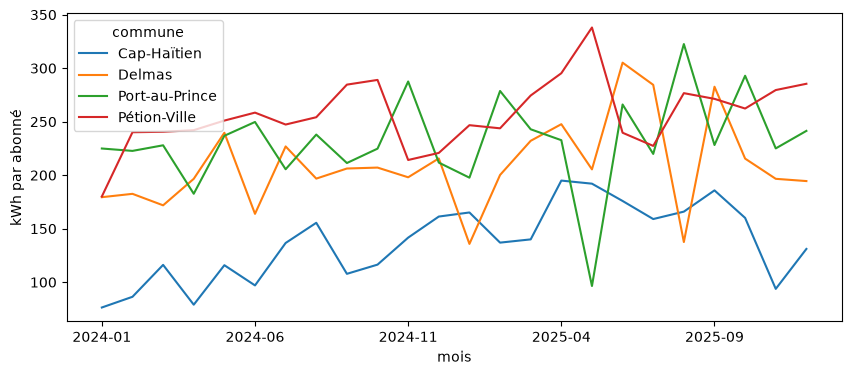

In [13]:
tab = df.pivot_table(index="commune", columns="annee", values="kwh", aggfunc="sum")
tab["hausse_pct"] = ((tab[2025] / tab[2024] - 1) * 100).round(1)
tab[[2024, 2025]] = (tab[[2024, 2025]] / 1e6).round(2)
print(tab.sort_values("hausse_pct", ascending=False))

courbes = df.groupby(["mois", "commune"])["kwh_par_abonne"].mean().unstack()
courbes.plot(figsize=(10, 4))
plt.ylabel("kWh par abonné")
plt.show()

**Ce qu'on en conclut :**

## 6. La consommation suit-elle la chaleur, ou les heures de courant ?

**14.** Quartiers résidentiels seulement : nuage de points des heures de courant contre la consommation par abonné. Puis la corrélation de la consommation par abonné avec `heures_courant`, et avec `temperature_c`.

Attendu : 0.76 avec les heures de courant, -0.15 avec la température.

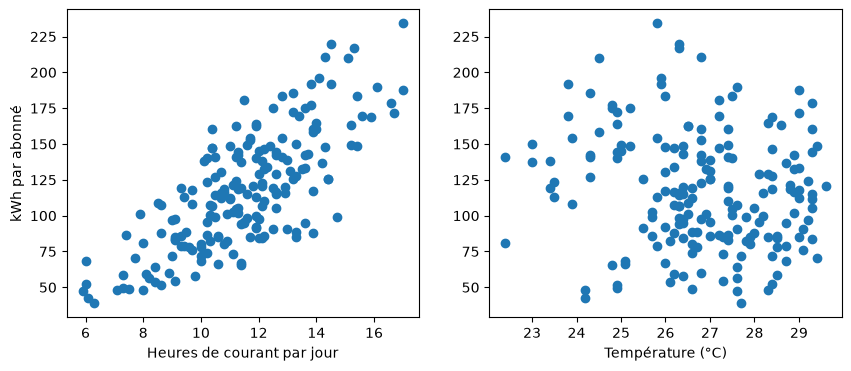

0.76
-0.15


In [14]:
res = df[df["type"] == "Résidentiel"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(res["heures_courant"], res["kwh_par_abonne"])
axes[0].set_xlabel("Heures de courant par jour")
axes[0].set_ylabel("kWh par abonné")
axes[1].scatter(res["temperature_c"], res["kwh_par_abonne"])
axes[1].set_xlabel("Température (°C)")
plt.show()

print(round(res["kwh_par_abonne"].corr(res["heures_courant"]), 2))
print(round(res["kwh_par_abonne"].corr(res["temperature_c"]), 2))

**Ce qu'on en conclut :**

## 7. Où les coupures sont-elles les plus longues ?

**15.** Les heures de courant : médiane, Q1, Q3 par commune, puis un histogramme pour Cap-Haïtien. Combien de relevés de 2025 ont moins de 8 heures de courant par jour, et dans quels quartiers ?

Attendu : médiane de 10.0 heures à Cap-Haïtien, entre 11.6 et 11.9 ailleurs ; 3 relevés de 2025, à Carénage, Delmas 33 et Rue 15.

                0.25  0.50  0.75
commune                         
Cap-Haïtien      8.3  10.0  11.7
Delmas          10.1  11.9  13.0
Port-au-Prince  10.7  11.6  13.1
Pétion-Ville    10.4  11.6  13.0


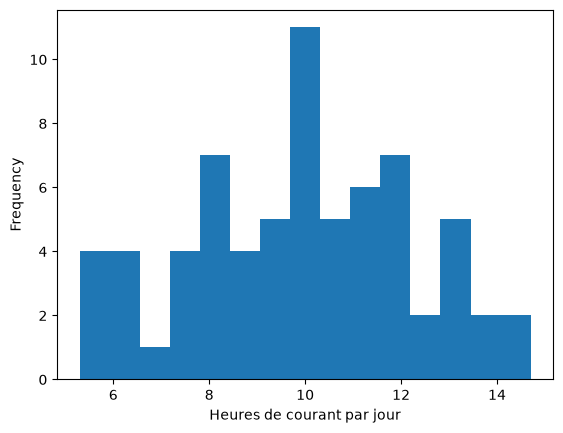

3
        mois   quartier      commune  heures_courant
81   2025-01  Delmas 33       Delmas             7.4
227  2025-08   Carénage  Cap-Haïtien             7.3
253  2025-11     Rue 15  Cap-Haïtien             5.9


In [15]:
print(df.groupby("commune")["heures_courant"].quantile([0.25, 0.5, 0.75]).unstack().round(1))

df.loc[df["commune"] == "Cap-Haïtien", "heures_courant"].plot.hist(bins=15)
plt.xlabel("Heures de courant par jour")
plt.show()

courts = df[(df["annee"] == 2025) & (df["heures_courant"] < 8)]
print(len(courts))
print(courts[["mois", "quartier", "commune", "heures_courant"]])

**Ce qu'on en conclut :**

## 8. Quels relevés sortent du lot ?

**16.** Les 3 plus grosses consommations de tout le fichier : mois, quartier, type, kwh.

Attendu : Delmas 33 en 2025-07 (742780), Centre-ville en 2024-11 (597730), Delmas 33 en 2025-09 (591420).

In [16]:
print(df.nlargest(3, "kwh")[["mois", "quartier", "type", "kwh"]])

       mois      quartier        type       kwh
87  2025-07     Delmas 33  Commercial  742780.0
56  2024-11  Centre-ville  Commercial  597730.0
88  2025-09     Delmas 33  Commercial  591420.0


**Ce qu'on en conclut :**

## 9. Conclusion

En trois phrases, répondez au directeur : la consommation suit-elle la chaleur, ou les heures de courant ? Citez vos chiffres, et dites ce qu'une corrélation ne permet pas de conclure.

## Et maintenant : le tableau de bord

Le directeur ne lit pas de notebook : il ouvre un lien. La suite se fait dans `app.py`, en six étapes, avec `uv run streamlit run app.py` ouvert à côté. Les étapes sont dans le README.